# Extra experiment 2: timbre and rhythm together

In the main experiment every feature set was tested on its own. The timbral model is weak (about 47%) but it hardly changes when the tempo changes. The rhythm model is strong (about 80%) but it collapses. A real system would use both, so here we ask: **when a model gets both kinds of features, does it still take the tempo shortcut, or does the timbre make it more robust?**

| Feature set | Inputs | What it is |
|---|---:|---|
| Timbral | 30 | MFCCs, zero-crossing rate, spectral centroid (mean and std), as in the main notebooks |
| Rhythm (as before) | 20 | cyclic tempogram, bar ratios, PLP confidence and PLP alignment, as in the main notebooks |
| Timbral + rhythm | 50 | both together |
| Timbral + rhythm, tempo removed | 50 | timbre plus the rhythm set with the shifted cyclic tempogram (see experiment 1) |
| Timbral + scale transform | 50 | timbre plus the scale transform (see experiment 1) |

Everything else is the same as in the main project and in experiment 1: same folds, both classifiers, nested tuning, the 13 audio versions.

One small difference from the main timbral notebooks: there the timbral models were trained on `ballroom_timbral_features.csv`, and here they are trained on the original rows of `all_versions_features.csv`. Both come from the same code, so the numbers are the same up to float rounding.

The rhythm features use the updated settings of `src/Rythm_extraction.py` (see section 4 of the main rhythm notebooks), with a tempo range of 60–220 BPM.

> **Earlier run, kept for reference.** This run used the updated rhythm extraction with a tempo range of 60–220 BPM, the value set in `src/Rythm_extraction.py`. The main run now uses 60–280 BPM: with 220 BPM, fast dances stretched by +10% (for example Quickstep at about 204–211 BPM, which becomes 224–232 BPM) go over the limit and the tempo estimate is forced to jump. The notebook paths point to the main project folder, so this copy is a record and is not meant to be run from here.

## 1. Imports

In [1]:
from pathlib import Path
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score

import features as F
import evaluation as E

# librosa 1.0 warns about arguments it passes to itself inside time_stretch; harmless, so hidden
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

`DATASET_DIR` is the only path you may need to change. The features of all 13 versions are saved in `all_versions_features.csv` the first time and reused after that, also by the other notebook in this folder.

In [2]:
DATASET_DIR = Path('../BallroomData')                  # the folder with the dance folders
FEATURES_PATH = Path('all_versions_features.csv')       # shared by both notebooks in this folder
MAIN_RESULTS_DIR = Path('../results')                   # results of the main notebooks, only used for checks
RESULTS_DIR = Path('results') / 'timbre_plus_rhythm'

EXPECTED_CLIPS = 698
N_JOBS = 8                          # CPU cores; set to 1 if parallel runs give problems
MODEL_NAMES = list(E.MODELS)        # Random Forest and SVM-RBF

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Clips and folds

Same clips and same five test folds as the main notebooks: stratified by dance, and the 13 known duplicate pairs always stay in one fold. If the main results are there, we check that every clip is in the same fold as before, so the numbers can be compared directly.

In [3]:
clips = E.find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, f'found {len(clips)} clips in {DATASET_DIR}'

folds = E.make_folds(clips)
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

main_folds = MAIN_RESULTS_DIR / 'rhythm_random_forest' / 'rhythm' / 'out_of_fold_predictions.csv'
if main_folds.is_file():
    before = pd.read_csv(main_folds).set_index('filename')['fold']
    assert (clips.set_index('filename')['fold'] == before.loc[clips['filename']]).all()
    print('every clip is in the same test fold as in the main notebooks')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

every clip is in the same test fold as in the main notebooks


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. Features of all 13 versions

Every clip is used in 13 versions: the original, six stretches (−10%, −5%, −2%, +2%, +5%, +10%) and six round trips (stretched and stretched back, so the tempo is the original one again). The code is in `features.py`. The timbral and rhythm features there are the same code as in the main notebooks, and the shifted cyclic tempogram and the scale transform are new.

Computing everything takes about 15 minutes. If the run stops, starting the cell again continues where it stopped.

In [4]:
if F.is_complete(FEATURES_PATH, clips):
    print(f'using the saved features in {FEATURES_PATH}')
else:
    start = time.perf_counter()
    F.extract_all_versions(clips, DATASET_DIR, FEATURES_PATH, n_jobs=N_JOBS)
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

versions = pd.read_csv(FEATURES_PATH)
feature_columns = F.TIMBRAL_COLUMNS + F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS + ['tau_hat'] \
    + F.SHIFTED_COLUMNS + F.SCALE_COLUMNS
assert not versions.duplicated(['filename', 'condition']).any()
assert np.isfinite(versions[feature_columns].to_numpy(dtype=float)).all(), 'NaN or infinite values in the features'

# the training table: features of the original audio, with labels and folds
data = (versions[versions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
print(f'{len(versions)} rows ({len(data)} clips x {len(F.CONDITIONS)} versions), {len(feature_columns)} feature columns')

using the saved features in all_versions_features.csv


9074 rows (698 clips x 13 versions), 86 feature columns


## 5. The feature sets

In [5]:
RHYTHM_COLUMNS = F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS
TEMPO_FREE_COLUMNS = F.SHIFTED_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS

FEATURE_SETS = {
    'Timbral': F.TIMBRAL_COLUMNS,
    'Rhythm (as before)': RHYTHM_COLUMNS,
    'Timbral + rhythm': F.TIMBRAL_COLUMNS + RHYTHM_COLUMNS,
    'Timbral + rhythm, tempo removed': F.TIMBRAL_COLUMNS + TEMPO_FREE_COLUMNS,
    'Timbral + scale transform': F.TIMBRAL_COLUMNS + F.SCALE_COLUMNS,
}
display(pd.Series({name: len(columns) for name, columns in FEATURE_SETS.items()}, name='inputs').to_frame())

,inputs
Timbral,30
Rhythm (as before),20
Timbral + rhythm,50
"Timbral + rhythm, tempo removed",50
Timbral + scale transform,50


## 6. Training

For every feature set and both classifiers we run the same nested cross-validation as the main notebooks: for each of the five test folds, a default model and a tuned model (grid search on three inner folds) are trained on the other four folds, using the original audio only. The grids are the ones from the rhythm notebooks. This cell takes a few minutes.

In [6]:
cv = {}
for model_name in MODEL_NAMES:
    for set_name, columns in FEATURE_SETS.items():
        print(f'{model_name}, {set_name} ({len(columns)} inputs)')
        cv[model_name, set_name] = E.run_nested_cv(data, columns, model_name, n_jobs=N_JOBS)

fold_metrics = pd.concat([result.fold_metrics.assign(model=model_name, feature_set=set_name)
                          for (model_name, set_name), result in cv.items()], ignore_index=True)
best_parameters = pd.concat([result.best_parameters.assign(model=model_name, feature_set=set_name)
                             for (model_name, set_name), result in cv.items()], ignore_index=True)
save(fold_metrics, 'fold_metrics.csv', index=False)
save(best_parameters, 'best_parameters.csv', index=False)

Random Forest, Timbral (30 inputs)


    tuned macro-F1 per fold: 0.438, 0.471, 0.499, 0.391, 0.522


Random Forest, Rhythm (as before) (20 inputs)


    tuned macro-F1 per fold: 0.842, 0.767, 0.834, 0.816, 0.837


Random Forest, Timbral + rhythm (50 inputs)


...

    tuned macro-F1 per fold: 0.833, 0.837, 0.850, 0.848, 0.874


SVM-RBF, Timbral + rhythm, tempo removed (50 inputs)


    tuned macro-F1 per fold: 0.766, 0.792, 0.746, 0.726, 0.721


SVM-RBF, Timbral + scale transform (50 inputs)


    tuned macro-F1 per fold: 0.794, 0.831, 0.834, 0.741, 0.834


## 7. Results on the original audio

Mean ± SD over the five test folds, tuned models. The timbral and rhythm rows are the reference and should be close to the main notebooks.

In [7]:
tuned = fold_metrics[fold_metrics['variant'] == 'Tuned']
summary = E.summarize_folds(tuned, ['accuracy', 'macro_f1'], by=('feature_set', 'model'))
save(summary, 'metric_summary.csv', index=False)

table = pd.DataFrame({model_name: [f'{100*m:.1f} ± {100*s:.1f}' for m, s in
                                   zip(rows['macro_f1_mean'], rows['macro_f1_std'])]
                      for model_name, rows in summary.groupby('model', sort=False)},
                     index=summary['feature_set'].unique())
table.index.name = 'macro-F1 (%)'
display(table)

,Random Forest,SVM-RBF
macro-F1 (%),,
Timbral,46.4 ± 5.1,47.2 ± 3.8
Rhythm (as before),81.9 ± 3.1,82.7 ± 3.0
Timbral + rhythm,85.1 ± 2.8,84.8 ± 1.6
"Timbral + rhythm, tempo removed",70.8 ± 2.2,75.0 ± 2.9
Timbral + scale transform,76.3 ± 3.3,80.7 ± 4.1


Timbre and rhythm together give the best scores on the original audio: about 85% with both classifiers, 2-3 points more than rhythm alone. So the timbre adds something that the rhythm features don't have.

Without the tempo, timbre plus the tempo-free rhythm set gets 71-75%, and timbre plus the scale transform gets 76% (Random Forest) and 81% (SVM).

The timbral reference row is 46.4% for the Random Forest here, against 47.2% in the main timbral notebook. This comes from the grid (here we use the larger grid of the rhythm notebooks) and from training on the recomputed original rows. The SVM gives the same 47.2% as before.

## 8. Results on the stretched audio

The fold models from the training section are used as they are; only `.predict()` is called on the features of the changed audio. For every model and feature set:

- the macro-F1 on the original audio and at −10% and +10%,
- the mean change over the six stretches and over the six round trips,
- "caused by tempo": the stretch change minus the round-trip change, the same measure as in the main README,
- the flip rate: the share of clips whose prediction changes when the audio is stretched.

The figure shows the tuned models. Left: stretched audio; right: round trip.

In [8]:
condition_metrics, held_out = {}, []
for (model_name, set_name), result in cv.items():
    metrics, predictions = E.evaluate_conditions(result, data, versions, F.CONDITIONS)
    condition_metrics[model_name, set_name] = metrics.assign(model=model_name, feature_set=set_name)
    held_out.append(predictions.assign(model=model_name, feature_set=set_name))

all_condition_metrics = pd.concat(condition_metrics.values(), ignore_index=True)
save(all_condition_metrics, 'stretch_fold_metrics.csv', index=False)
save(pd.concat(held_out, ignore_index=True), 'held_out_predictions_tuned.csv', index=False)

robustness = E.summarize_folds(all_condition_metrics, ['accuracy', 'macro_f1', 'flip_rate', 'macro_f1_change_pp'],
                               by=('model', 'feature_set', 'variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
save(robustness, 'robustness_summary.csv', index=False)

tempo_effect = pd.DataFrame([{'model': model_name, 'feature set': set_name, **E.tempo_effect_row(metrics)}
                             for (model_name, set_name), metrics in condition_metrics.items()])
tempo_effect = tempo_effect.set_index(['model', 'feature set'])
save(tempo_effect, 'tempo_effect.csv')
display(tempo_effect.round(1))

original macro-F1 (%)  \
model         feature set                                              
Random Forest Timbral                                           46.4   
              Rhythm (as before)                                81.9   
              Timbral + rhythm                                  85.1   
              Timbral + rhythm, tempo removed                   70.8   
              Timbral + scale transform                         76.3   
SVM-RBF       Timbral                                           47.2   
              Rhythm (as before)                                82.7   
              Timbral + rhythm                                  84.8   
              Timbral + rhythm, tempo removed                   75.0   
              Timbral + scale transform                         80.7   

                                               at -10% (%)  at +10% (%)  \
model         feature set                                                 
Random Forest Timbral                                 46.0         45.3   
              Rhythm (as before)                      21.6         15.1   
              Timbral + rhythm                        31.4         29.3   
              Timbral + rhythm, tempo removed         52.4         62.2   
              Timbral + scale transform               64.0         60.2   
SVM-RBF       Timbral                                 47.7         47.0   
              Rhythm (as before)                      33.2         15.9   
              Timbral + rhythm                        43.2         23.7   
              Timbral + rhythm, tempo removed         57.9         65.4   
              Timbral + scale transform               70.4         65.3   

                                               mean change, stretch (pp)  \
model         feature set                                                  
Random Forest Timbral                                               -0.9   
              Rhythm (as before)                                   -39.1   
              Timbral + rhythm                                     -30.1   
              Timbral + rhythm, tempo removed                      -10.3   
              Timbral + scale transform                            -14.3   
SVM-RBF       Timbral                                                0.2   
              Rhythm (as before)                                   -38.9   
              Timbral + rhythm                                     -26.7   
              Timbral + rhythm, tempo removed                      -10.1   
              Timbral + scale transform                            -12.6   

                                               mean change, round trip (pp)  \
model         feature set                                                     
Random Forest Timbral                                                  -3.7   
              Rhythm (as before)                                      -11.9   
              Timbral + rhythm                                         -3.5   
              Timbral + rhythm, tempo removed                          -7.6   
              Timbral + scale transform                               -28.0   
SVM-RBF       Timbral                                                  -2.1   
              Rhythm (as before)                                      -12.2   
              Timbral + rhythm                                         -2.0   
              Timbral + rhythm, tempo removed                          -6.6   
              Timbral + scale transform                               -20.8   

                                               caused by tempo (pp)  \
model         feature set                                             
Random Forest Timbral                                           2.7   
              Rhythm (as before)                              -27.1   
              Timbral + rhythm                                -26.5   
              Timbral + rhythm, tempo removed                  -

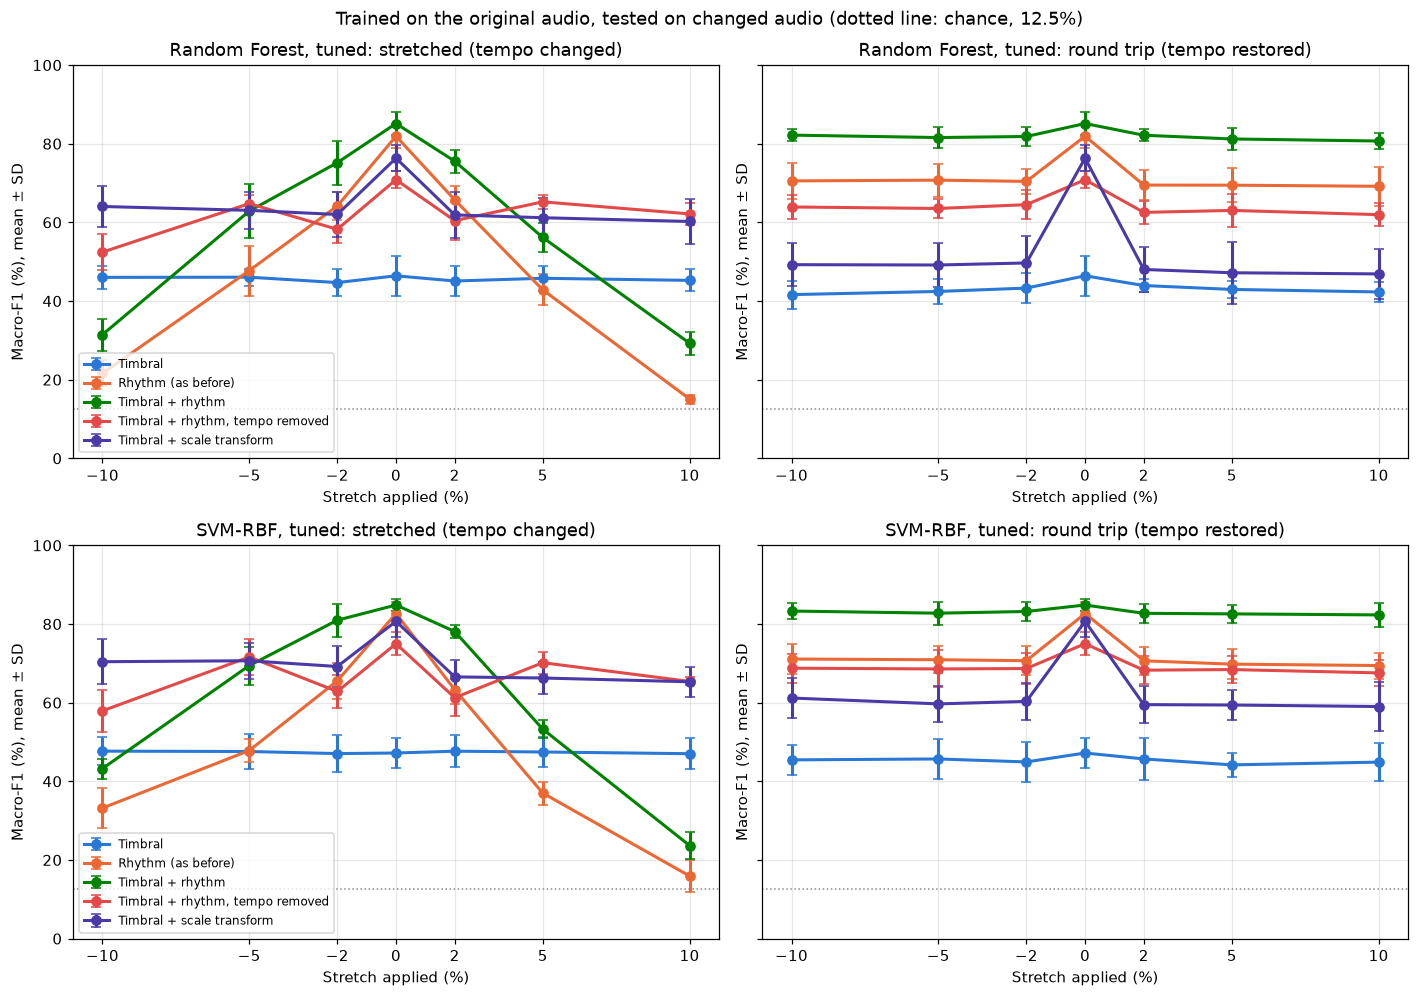

In [9]:
figure, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(13, 4.6*len(MODEL_NAMES)), sharey=True)
for row, model_name in enumerate(MODEL_NAMES):
    curves = {set_name: condition_metrics[model_name, set_name] for set_name in FEATURE_SETS}
    E.plot_robustness(curves, {name: E.SET_COLORS[name] for name in FEATURE_SETS}, model_name, axes[row])
figure.suptitle('Trained on the original audio, tested on changed audio (dotted line: chance, 12.5%)')
figure.tight_layout()
save_figure(figure, 'robustness_curves.png')

Timbral + rhythm: adding timbre helps only a little against the tempo shortcut. The model still loses about 25-27 points because of the tempo, and at +10% it falls to 24-29% (rhythm alone: 15-16%). So even though the model also has the stable timbral features, it mostly relies on the tempo when it can.

Timbral + rhythm, tempo removed: this is the most robust combination with rhythm features. The part of the drop caused by the tempo is only 3-4 points, and the model stays between 52% and 72% for every stretch. At +10% it gets 62-65% against 24-29% for timbral + rhythm, although it is 10-14 points worse on the original audio.

Timbral + scale transform: like the scale transform alone in experiment 1, it does not react to the tempo but loses a lot through the processing (21-28 points in the round trip). Under stretching it still stays at 60-71%, which makes it the best model at −10%.

So there is a clear trade-off: the tempo gives the best score on unchanged audio, and removing it gives a model that keeps working when the tempo changes.

## 9. How much do the combined models use the timbre?

Group permutation importance of the tuned combined models: we shuffle one family of inputs across the test clips and measure how much macro-F1 drops. If the rhythm family causes a big drop and the timbre families a small one, the model mostly ignores the timbre even though it is there.

In [10]:
TIMBRAL_GROUPS = {'MFCC': [c for c in F.TIMBRAL_COLUMNS if c.startswith('mfcc_')],
                  'Zero-crossing rate': ['zcr_mean', 'zcr_std'],
                  'Spectral centroid': ['spectral_centroid_mean', 'spectral_centroid_std']}
RHYTHM_GROUPS = {'Bar ratios': F.RATIO_COLUMNS, 'PLP': F.PLP_COLUMNS}
GROUPS = {
    'Timbral + rhythm': {**TIMBRAL_GROUPS, 'Cyclic tempogram': F.CYCLIC_COLUMNS, **RHYTHM_GROUPS},
    'Timbral + rhythm, tempo removed': {**TIMBRAL_GROUPS, 'Shifted cyclic tempogram': F.SHIFTED_COLUMNS, **RHYTHM_GROUPS},
    'Timbral + scale transform': {**TIMBRAL_GROUPS, 'Scale transform': F.SCALE_COLUMNS},
}

rows = []
for set_name, groups in GROUPS.items():
    for model_name in MODEL_NAMES:
        importance = E.group_importance(cv[model_name, set_name], data, groups)
        for family, values in importance.iterrows():
            rows.append({'feature set': set_name, 'model': model_name, 'family': family,
                         'macro-F1 drop (pp)': 100*values['mean'], 'SD (pp)': 100*values['std']})
importance = pd.DataFrame(rows)
save(importance, 'feature_family_importance.csv', index=False)
display(importance.pivot_table(index=['feature set', 'family'], columns='model', values='macro-F1 drop (pp)',
                               sort=False).round(1))

model                                                     Random Forest  \
feature set                     family                                    
Timbral + rhythm                Cyclic tempogram                   61.6   
                                MFCC                                6.6   
                                Spectral centroid                   2.7   
                                PLP                                 2.5   
                                Bar ratios                          0.3   
                                Zero-crossing rate                 -0.3   
Timbral + rhythm, tempo removed MFCC                               15.8   
                                Spectral centroid                   2.7   
                                PLP                                 8.8   
                                Bar ratios                          2.4   
                                Zero-crossing rate                  0.2   
                                Shifted cyclic tempogram           30.2   
Timbral + scale transform       MFCC                               13.3   
                                Spectral centroid                   3.4   
                                Zero-crossing rate                  0.7   
                                Scale transform                    49.3   

model                                                     SVM-RBF  
feature set                     family                             
Timbral + rhythm                Cyclic tempogram             54.9  
                                MFCC                         20.9  
                                Spectral centroid             0.7  
                                PLP                           3.1  
                                Bar ratios                    0.5  
                                Zero-crossing rate           -0.1  
Timbral + rhythm, tempo removed MFCC                         27.4  
                                Spectral centroid             2.2  
                                PLP                           9.3  
                                Bar ratios                    2.5  
                                Zero-crossing rate            0.3  
                                Shifted cyclic tempogram     32.3  
Timbral + scale transform       MFCC                         30.3  
                                Spectral centroid             2.5  
                                Zero-crossing rate            2.2  
                                Scale transform              49.8

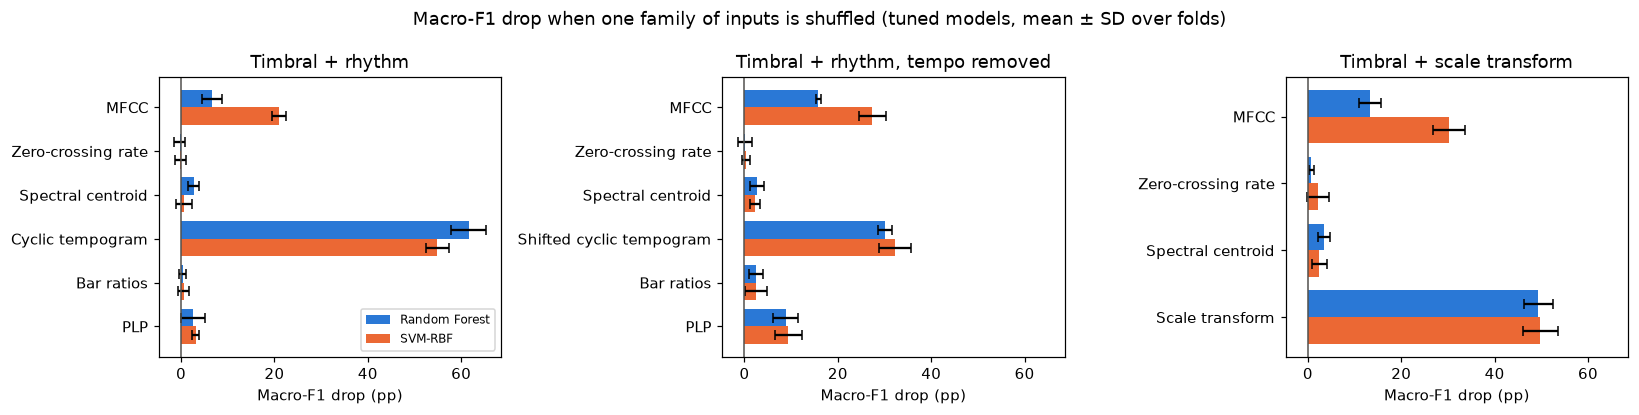

In [11]:
figure, axes = plt.subplots(1, len(GROUPS), figsize=(15, 3.8), sharex=True)
for axis, (set_name, groups) in zip(axes, GROUPS.items()):
    rows = importance[importance['feature set'] == set_name]
    families = list(groups)
    positions = np.arange(len(families))
    for offset, model_name, color in zip([-0.2, 0.2], MODEL_NAMES, [E.SET_COLORS['Timbral'], E.SET_COLORS['Rhythm (as before)']]):
        values = rows[rows['model'] == model_name].set_index('family').loc[families]
        axis.barh(positions + offset, values['macro-F1 drop (pp)'], height=0.4, xerr=values['SD (pp)'],
                  color=color, capsize=3, label=model_name)
    axis.set_yticks(positions, families)
    axis.invert_yaxis()
    axis.axvline(0, color='#52514e', linewidth=1)
    axis.set(title=set_name, xlabel='Macro-F1 drop (pp)')
axes[0].legend(loc='lower right', fontsize=8)
figure.suptitle('Macro-F1 drop when one family of inputs is shuffled (tuned models, mean ± SD over folds)')
figure.tight_layout()
save_figure(figure, 'feature_family_importance.png')

In timbral + rhythm, the cyclic tempogram is by far the most important family (55-62 points), and the MFCCs matter much less (7 points for the Random Forest, 21 for the SVM). So the models mostly ignore the timbre when the tempo class is available.

When the tempo is removed, the MFCCs become more important (16 and 27 points) and share the work with the shifted tempogram (30-32 points) and the two PLP inputs (9 points). The zero-crossing rate and the spectral centroid add almost nothing next to the MFCCs.

## 10. Summary

- Timbre and rhythm together are the best combination on unchanged audio (about 85%), but the combined model still takes the tempo shortcut: it loses about 25 points when the tempo changes, almost as much as rhythm alone (27 points). Having stable timbral features available does not stop the model from relying on the tempo.
- With the tempo removed from the rhythm part, the combination still gets 71-75% and loses only 3-4 points to tempo changes.
- Timbre plus the scale transform reaches 76-81% without any tempo information, but it is sensitive to the stretching artifacts, like the scale transform alone.
- Together with experiment 1 this gives a clear picture: about 10-20 points of the Ballroom score come from the tempo, and the rest can be reached with features that do not depend on the tempo.

## 11. Everything in one picture

Every point is one feature set, averaged over the two classifiers. The horizontal axis is the score on the original audio, the vertical axis the average score on the six stretched versions (±2%, ±5%, ±10%). A point on the diagonal loses nothing when the tempo changes; the further below the diagonal, the more fragile the model. Grey points are the feature sets of the main experiment, orange points experiment 1 and blue points this notebook.

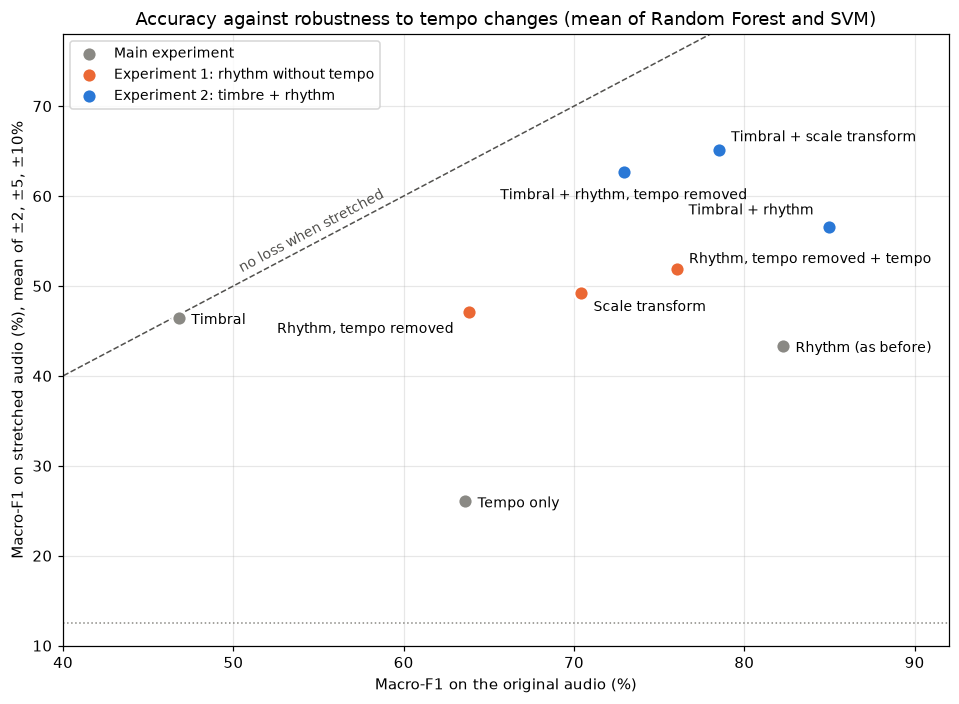

,original macro-F1 (%),stretched macro-F1 (%)
feature set,,
Rhythm (as before),82.3,43.3
Tempo only,63.6,26.1
"Rhythm, tempo removed",63.8,47.2
Scale transform,70.4,49.2
"Rhythm, tempo removed + tempo",76.0,51.9
Timbral,46.8,46.4
Timbral + rhythm,85.0,56.6
"Timbral + rhythm, tempo removed",72.9,62.7
Timbral + scale transform,78.5,65.1


In [12]:
experiment_1 = pd.read_csv('results/rhythm_without_tempo/tempo_effect.csv')
experiment_2 = pd.read_csv(RESULTS_DIR / 'tempo_effect.csv')
both = pd.concat([experiment_1, experiment_2]).drop_duplicates(['model', 'feature set'])
both['stretched macro-F1 (%)'] = both['original macro-F1 (%)'] + both['mean change, stretch (pp)']
points = both.groupby('feature set', sort=False)[['original macro-F1 (%)', 'stretched macro-F1 (%)']].mean()

GROUPS = {'Main experiment': (['Timbral', 'Tempo only', 'Rhythm (as before)'], '#8a8984'),
          'Experiment 1: rhythm without tempo': (['Rhythm, tempo removed', 'Scale transform',
                                                  'Rhythm, tempo removed + tempo'], '#eb6834'),
          'Experiment 2: timbre + rhythm': (['Timbral + rhythm', 'Timbral + rhythm, tempo removed',
                                             'Timbral + scale transform'], '#2a78d6')}
LABEL_POSITIONS = {'Timbral': (8, -4, 'left'), 'Tempo only': (8, -4, 'left'), 'Rhythm (as before)': (8, -4, 'left'),
                   'Rhythm, tempo removed': (-10, -14, 'right'), 'Scale transform': (8, -12, 'left'),
                   'Rhythm, tempo removed + tempo': (8, 4, 'left'), 'Timbral + rhythm': (-10, 8, 'right'),
                   'Timbral + rhythm, tempo removed': (0, -18, 'center'), 'Timbral + scale transform': (8, 6, 'left')}

figure, axis = plt.subplots(figsize=(9, 6.5))
axis.plot([0, 100], [0, 100], color='#52514e', linestyle='--', linewidth=1)
axis.text(50.5, 51.5, 'no loss when stretched', rotation=45, transform_rotates_text=True,
          rotation_mode='anchor', color='#52514e', fontsize=9)
axis.axhline(12.5, color='#8a8984', linestyle=':', linewidth=1)
for group, (set_names, color) in GROUPS.items():
    part = points.loc[set_names]
    axis.scatter(part['original macro-F1 (%)'], part['stretched macro-F1 (%)'], s=90, color=color,
                 edgecolor='white', linewidth=1.5, zorder=3, label=group)
    for set_name, row in part.iterrows():
        dx, dy, alignment = LABEL_POSITIONS[set_name]
        axis.annotate(set_name, (row['original macro-F1 (%)'], row['stretched macro-F1 (%)']),
                      xytext=(dx, dy), textcoords='offset points', fontsize=9, ha=alignment)
axis.set(xlim=(40, 92), ylim=(10, 78), xlabel='Macro-F1 on the original audio (%)',
         ylabel='Macro-F1 on stretched audio (%), mean of ±2, ±5, ±10%',
         title='Accuracy against robustness to tempo changes (mean of Random Forest and SVM)')
axis.grid(alpha=0.3)
axis.legend(loc='upper left', fontsize=9)
figure.tight_layout()
figure.savefig('results/summary_tradeoff.png', bbox_inches='tight')
plt.show()
display(points.round(1))